<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 3. Preprocessing

Hier soll noch eine Beschreibung hin

## 3.2. Datenqualität

### 3.2.1. Überblick
Bevor statistische Analysen oder Modellierungen durchgeführt werden, muss ein grundlegendes Verständnis des verwendeten Datensatzes geschaffen werden. In diesem Abschnitt werden Struktur, Umfang und Qualität der zugrunde liegenden Kursdaten untersucht.

Die verwendeten Daten bestehen aus hochfrequenten 1-Minuten-Preisen der im S&P 500 enthaltenen Aktien. Der rohe Datensatz umfasst Kurse vom **07. November 2025** bis zum **DATUM NOCH NICHT DEFINIERT** und enthält insgesamt mehrere millionen Zeilen.

Zunächst werden grundlegende Kennzahlen wie die Anzahl der Zeilen und der enthaltenen Ticker (Symbole) ermittelt. Anschließend erfolgt eine Prüfung auf fehlende Werte, um Datenlücken oder Unstimmigkeiten im Datensatz zu identifizieren.

Diese Analyse dient als Grundlage für alle weiteren Schritte der explorativen Datenanalyse, da nur ein qualitativ hochwertiger Datensatz verlässliche Ergebnisse liefern kann.

In [1]:
from pairs_trading import data_io as io
from pairs_trading import preprocessing as pp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns

In [2]:
df = io.load_unprocessed_data()

Anzahl Zeilen gesamt: 6,697,777
Anzahl Ticker gesamt: 506
Anzahl Handelstage: 35


,symbol,datetime,open,high,low,close,volume,date
0,MMM,2025-11-07 14:30:00,163.910004,163.929993,163.389999,163.820007,45015.0,2025-11-07
1,CL,2025-11-07 14:30:00,77.849998,77.894997,77.470001,77.660004,143903.0,2025-11-07
2,USB,2025-11-07 14:30:00,46.619999,46.889999,46.619999,46.840000,148773.0,2025-11-07
3,CMCSA,2025-11-07 14:30:00,27.559999,27.559999,27.400000,27.545000,348544.0,2025-11-07
4,CAG,2025-11-07 14:30:00,16.740000,16.760000,16.690001,16.754999,191545.0,2025-11-07


Da in der folgenden Analyse ausschließlich Aktien betrachtet werden sollen, die über den gesamten Beobachtungszeitraum Bestandteil des S&P 500 waren, werden zunächst alle Symbole entfernt, die erst während des Zeitraums aufgenommen wurden oder vorzeitig aus dem Index ausgeschieden sind.

In [3]:
df, removed_symbols = pp.filter_symbols_by_full_coverage(df)

print(f"Anzahl entfernte Ticker: {len(removed_symbols)}")
print(f"Anzahl verbleibende Ticker: {df['symbol'].nunique()}")

Anzahl entfernte Ticker: 11
Anzahl verbleibende Ticker: 495


### 3.2.2. Fehlende Werte
Ein wesentlicher Aspekt der Datenqualität ist das Vorhandensein fehlender Werte.  
Fehlende oder unvollständige Kursdaten können sowohl die Berechnung statistischer Kennzahlen als auch die Ergebnisse maschineller Lernverfahren erheblich beeinflussen.  
In diesem Schritt wird überprüft, in welchem Umfang solche Datenlücken existieren und wie sie sich über die Aktien verteilen.

Zunächst werden die Spalten des Datensatzes auf fehlende Werte (`NaN`) überprüft, um einen allgemeinen Überblick zu gewinnen. Anschließend wird die Anzahl der verfügbaren Datenpunkte je Aktie bestimmt, um potenziell unvollständige Zeitreihen zu identifizieren.

Diese Analysen ermöglichen es, die Datenqualität vor der Modellierung quantitativ zu bewerten und entscheiden zu können, ob bestimmte Symbole aufgrund von Datenlücken ausgeschlossen oder bearbeitet werden müssen.


Es gibt 495 Aktien mit mindestens einem fehlenden Wert.

Top 5 betroffene Ticker (fehlende Zeilen):
symbol
ERIE    7529
AIZ     7288
NDSN    6604
TPL     6600
CINF    6002
dtype: int64


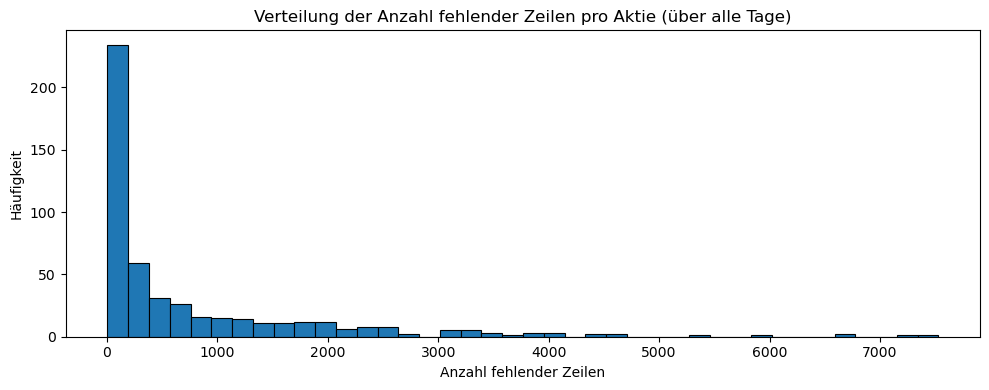

In [4]:
missing = pp.analyze_missing_values(df, top_n=5, bins=40, show_plot=True)

Die meisten Aktien haben nur sehr wenige fehlende Datenpunkte, einige wenige jedoch deutlich mehr.

Nachdem festgestellt wurde, welche Aktien unvollständige Zeitreihen besitzen, wird nun untersucht, **wann** diese Datenlücken im jeweiligen Tagesverlauf auftreten. Diese Analyse hilft zu erkennen, ob die fehlenden Werte zufällig verteilt sind oder ob sie zu bestimmten Zeiten des Handelstages gehäuft vorkommen.

Ein gehäuftes Auftreten zu bestimmten Uhrzeiten kann auf **technische Ursachen** (z. B. Marktpause) oder **marktbedingte Phasen geringer Aktivität** hindeuten.

Zur Analyse wird der Zeitstempel der Daten extrahiert und auf Minutenebene aggregiert. Anschließend wird gezählt, wie viele Werte zu jedem Zeitpunkt fehlen. Das Ergebnis wird in Form eines Liniendiagramms visualisiert, um die Häufigkeit fehlender Werte über den jeweiligen Tag hinweg zu untersuchen. Die Legende zum Diagramm wurde zur Übersichtlichkeit auskommentiert.

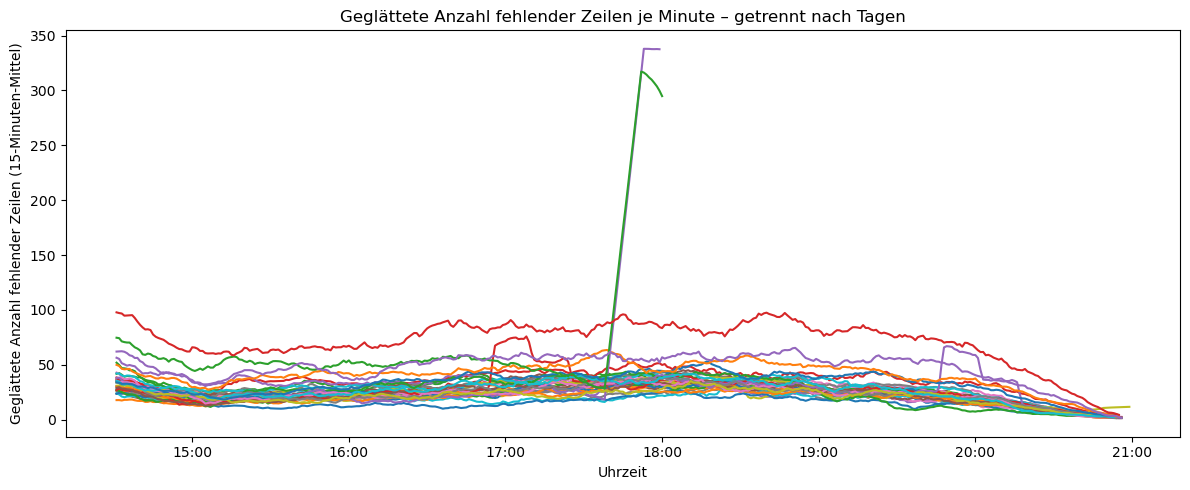

,rows_total,rows_missing,missing_%
2025-11-28,104444,11417,10.931217
2025-12-24,104445,14516,13.898224
2025-11-11,193154,11243,5.820744
2025-11-20,193535,7232,3.736792
2025-12-10,193540,10224,5.282629


In [5]:
coverage = pp.analyze_missing_coverage(
    df,
    smoothing_window=15,
    show_plot=True,
    print_table=False
)
coverage.sort_values("rows_total").head(5)

Es ist zu erkennen, dass es drei Tage gibt, die herausstechen:
 - **28.11.2025**, Thanksgiving, Early-Close
 - **24.12.2025**, Weihnachten, Early-Close
 - **26.12.2025**, kurz nach Weihnachten, wenig Markthandel

https://www.nasdaqtrader.com/trader.aspx?id=calendar

Einfachheitshalber werden diese Tage aus dem Datensatz gestrichen und dann ergibt sich nun das folgende Diagramm.

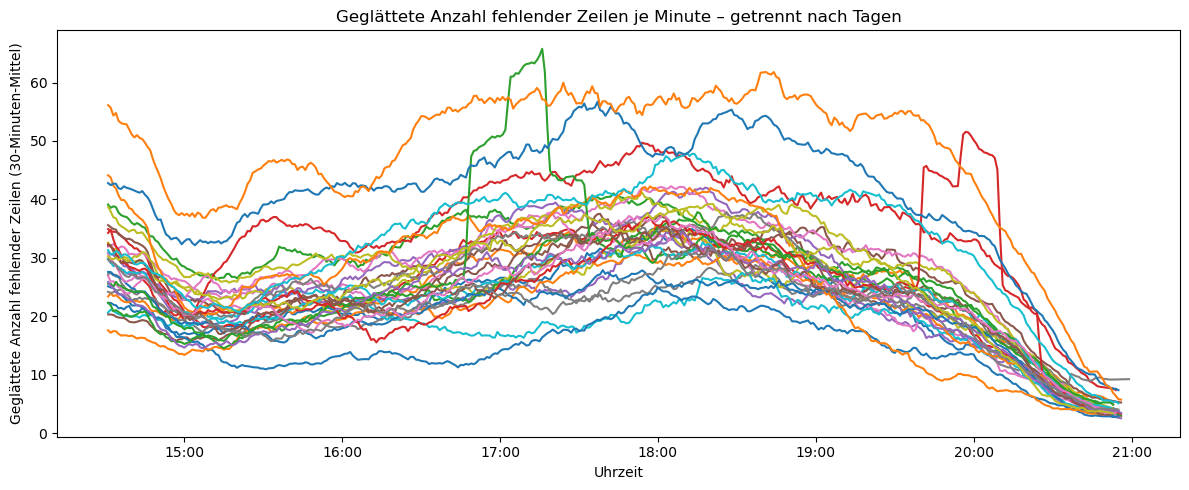

In [6]:
# Early-close Tage manuell entfernen
early_close_days = [
    pd.to_datetime("2025-11-28").date(),
    pd.to_datetime("2025-12-24").date(),
    pd.to_datetime("2025-12-26").date(),
]

# Datum aus der datetime-Spalte ableiten und Maske bauen
dt = pd.to_datetime(df["datetime"], errors="coerce")
mask_keep = ~dt.dt.date.isin(early_close_days)

# Gefiltertes DataFrame, einfachheitshalber so genannt
df_no_early_close = df.loc[mask_keep].copy()

# Coverage nach Entfernen der Early-close Days neu berechnen
coverage_no_early_close = pp.analyze_missing_coverage(
    df_no_early_close,
    smoothing_window=30,
    show_plot=True,
    print_table=False
)

Es ist ein Trend zu erkennen in den fehlenden Daten. Die Hauptsache für die EDA dieses Projekts ist, dass es keinen weiteren auffälligen Ausreisser (Tag) vorkommt. Die Daten wurden auf den Tag aggregiert, um den Trend genauer untersuchen zu können, jedoch liegt dies nicht im Rahmen dieses Projekts. Der Trend ist im folgenden Histogramm besser zu erkennen:

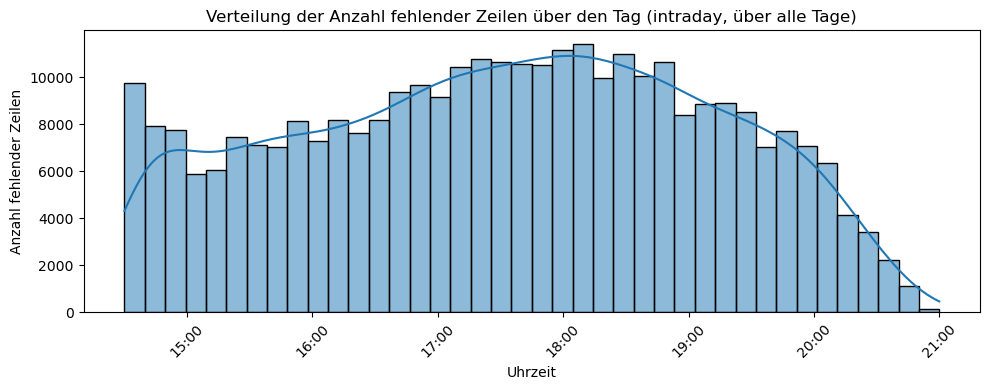

In [7]:
missing_time_df = pp.plot_intraday_missing_distribution(df_no_early_close, bins=40, kde=True)

### 3.2.3. Datenlücken

Im folgenden wird untersucht, ob und wie diese fehlenden Daten konsekutiv vorkommen. Diese Lücken sind ein Problem, falls sie zu gross werden. Es ist zu bemerken, dass die Zahlen hier nicht auf den Tag aggregiert wurden, wie vorhin.

In der folgenden Analyse werden **Lücken (NaN-Werte)** in den Kursdaten aller Aktien untersucht. Die Funktion `analyze_nan_luecken_global(df)` sucht für jede Aktie zusammenhängende Bereiche mit fehlenden Werten und berechnet die Länge der Lücke in Minuten und die relative Preisänderung zwischen den Zeitpunkten davor und danach.

Gefundene Lücken insgesamt: 230653



,gap_len,rel_change
count,230653.000000,230653.000000
mean,2.377303,0.000002
std,0.940928,0.001004
min,2.000000,-0.020662
25%,2.000000,-0.000411
50%,2.000000,0.000000
75%,2.000000,0.000411
max,27.000000,0.051555


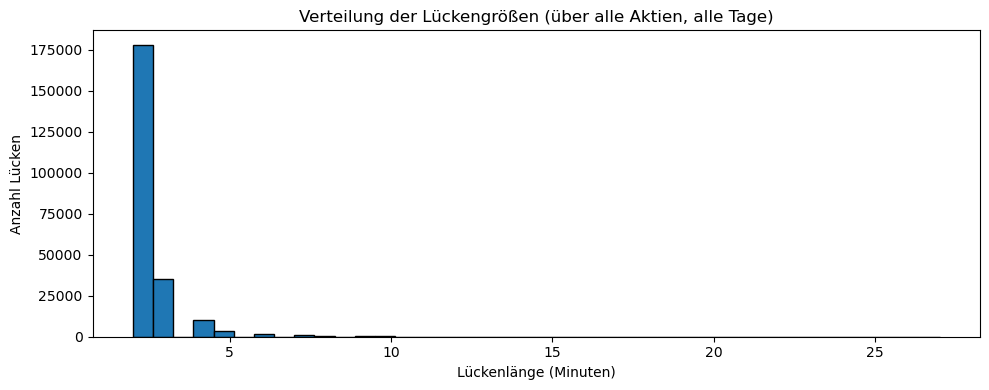

In [8]:
nan_gaps_all = pp.analyze_nan_gaps_global(df_no_early_close)
print(f"Gefundene Lücken insgesamt: {len(nan_gaps_all)}\n")
display(nan_gaps_all.describe())
pp.plot_gap_length_hist(nan_gaps_all, bins=40, round_to_int=True)

Die statistische Auswertung zeigt, dass die meisten Lücken kurz sind und der Datensatz sollte deshalb kein Problem darstellen.

Das Histogramm visualisiert die Verteilung der Lückengrößen. Das Histogramm zeigt nicht besonders viel, aber den wesentlichen Punkt wird gut demonstriert: Der Großteil der Lücken beträgt nur 2 Minuten, längere Ausfälle sind sehr selten. Das deutet darauf hin, dass Datenunterbrechungen kurz und regelmäßig, aber nicht gravierend lang auftreten.

Probleme bereiten die grossen Lückengrössen aus, nicht die Kleinen. Nun werden folgende drei Tabellen ausgegeben:
 - Anzahl vorkommender Lücken pro Lückengrösse (in Minuten)
 - Anzahl Aktien mit mindestens einer Lücke > 5 Minuten
 - Anzahl Aktien mit mindestens einer Lücke > X Minuten (als Funktion von X)

In [9]:
gap_counts = pp.gap_len_counts(nan_gaps_all, min_gap=0, round_to_int=True)
print("Anzahl vorkommender Lücken pro Lückengröße (in Minuten):\n")
display(gap_counts.head(10))

long_gaps_tbl = pp.long_gap_summary(nan_gaps_all, threshold_min=5, round_to_int=True)
print(f"Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: {len(long_gaps_tbl)}\n")
display(long_gaps_tbl.head(10))

gap_stats = pp.gap_stats_stocks_with_min_gap(nan_gaps_all, round_to_int=True)
print("Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:\n")
display(gap_stats)

Anzahl vorkommender Lücken pro Lückengröße (in Minuten):



,gap_len,count
0,2,177865
1,3,35091
2,4,10190
3,5,3786
4,6,1683
5,7,849
6,8,493
7,9,249
8,10,155
9,11,95


Anzahl Aktien mit mindestens einer Lücke > 5 Minuten: 138



,symbol,n_gaps,max_gap
0,AIZ,365,27
1,XYZ,1,23
2,ERIE,421,22
3,NDSN,300,21
4,TPL,322,19
5,IEX,96,19
6,BR,71,18
7,CBOE,97,17
8,GL,153,15
9,GWW,99,15


Anzahl Aktien mit mindestens einer Lücke ≥ X Minuten:



,gap_length_min,n_stocks
0,1,495
1,2,495
2,3,494
3,4,262
4,5,176
5,6,138
6,7,103
7,8,78
8,9,51
9,10,42


Es ist zu interessant, dass jede Aktie mindestens eine Lücke von 2 Minuten hat. Um die letzte Tabelle zu visualisieren, wurde folgendes Diagramm erstellt:

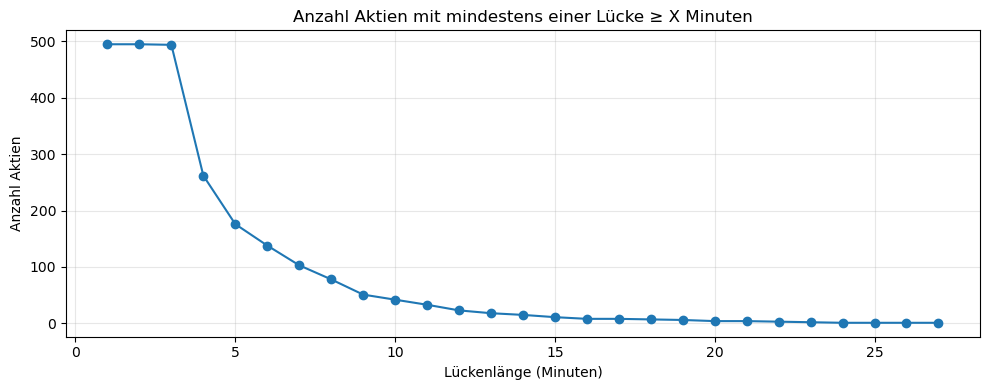

In [10]:
pp.plot_stocks_vs_gap_threshold(gap_stats)

Die linke Hälfte des Plots entspricht der Erwartung, dass die Anzahl der Aktien mit einer Lückengrösse von X abflachend absteigt. Dieses Verhalten geht nach einem unerwartetem Sprung weiter.

Dieses Diagramm sollte die Grundlage sein für die Entscheidung, welche Aktien aus dem Datensatz ausgeschlossen werden sollten. Der unerklärte Sprung erleichtert diese Entscheidung.

Es wurde entschieden, dass die Aktien mit Datenlücken, die mindestens 16 Minuten lang sind, entfernt werden.

### 3.2.3. Datenbereinigung
Da nun festgestellt wurde wie die Datenlücken aussehen werden Aktien mit zu grossen Datenlücken entfernt.

In [11]:
minute_threshold = 16

symbols_with_long_gaps = pp.find_symbols_with_long_gaps(
    nan_gaps_all,
    min_gap_len=minute_threshold,
)

print(f"Anzahl Aktien mit mindestens einer Lücke ≥ {minute_threshold} Minuten: {len(symbols_with_long_gaps)}")

df_clean = pp.drop_symbols(
    df_no_early_close,
    symbols_with_long_gaps,
    sort_by=["datetime"],
)

print(f"Verbleibende Aktien nach Filterung: {df_clean['symbol'].nunique()}")
print(f"Zeilen nach Filterung: {len(df_clean):,}")

Anzahl Aktien mit mindestens einer Lücke ≥ 16 Minuten: 8
Verbleibende Aktien nach Filterung: 487
Zeilen nach Filterung: 6,093,293


Die kleinen Datenlücken werden im folgenden Schritt bereinigt. Datenlücken werden gefüllt indem, sie interpoliert werden und in Edge-Cases wird von vorne/hinten aufgefüllt. Dazu wird die ('close_filled') hinzugefügt, um die Daten nicht zu verfälschen.

In [12]:
df_filled = pp.fill_close_gaps_per_symbol(
    df_clean,
    value_col="close",
    out_col="close_filled",
)

print("Fehlende Werte im Original (gefiltert):", df_clean["close"].isna().sum())
print("Fehlende Werte in close_filled:", df_filled["close_filled"].isna().sum())

Fehlende Werte im Original (gefiltert): 280206
Fehlende Werte in close_filled: 0


Da nun keine Datenlücken vorkommen, wird nun die Länge Daten pro Aktie analysiert.

In [13]:
lengths = pp.symbol_lengths(df_filled)

print("\nHäufigste Längen:")
print(lengths.value_counts().sort_index())

df_filled.head()


Häufigste Längen:
12503      1
12508      3
12509      2
12510      6
12511     12
12512    463
dtype: int64


,datetime,symbol,open,high,low,close,volume,date,close_filled
0,2025-11-07 14:30:00,A,146.520004,147.119995,145.729996,145.729996,13361.0,2025-11-07,145.729996
1,2025-11-07 14:31:00,A,NaN,NaN,NaN,NaN,NaN,2025-11-07,145.909996
2,2025-11-07 14:32:00,A,146.089996,146.089996,146.089996,146.089996,427.0,2025-11-07,146.089996
3,2025-11-07 14:33:00,A,NaN,NaN,NaN,NaN,NaN,2025-11-07,146.069847
4,2025-11-07 14:34:00,A,146.049698,146.049698,146.049698,146.049698,1387.0,2025-11-07,146.049698


Vereinzelte Aktien haben ausreissende Datenlängen. Diese sind sehr problematisch. Zunächst wird untersucht, um welche Aktien es sich handelt.

In [14]:
expected_length = pp.expected_length_mode(lengths)
print(f"Erwartete Anzahl Zeilen pro Symbol: {expected_length}\n")

bad_symbols = pp.symbols_with_unexpected_length(lengths, expected_length)

if bad_symbols.empty:
    print("Alle Symbole haben die erwartete Länge – keine Entfernung nötig.")
    symbols_to_drop = []
else:
    print(f"{len(bad_symbols)} Symbole mit abweichender Länge gefunden:\n")
    display(bad_symbols)

    symbols_to_drop = bad_symbols.index.tolist()
    print(f"\nZu entfernende Symbole (für nächste Zelle):")
    print(symbols_to_drop)

Erwartete Anzahl Zeilen pro Symbol: 12512

24 Symbole mit abweichender Länge gefunden:



symbol
FICO    12503
JBL     12508
CMG     12508
CBRE    12508
ZTS     12509
ABT     12509
RL      12510
CNC     12510
CHD     12510
MSI     12510
VLTO    12510
MTB     12510
FE      12511
WSM     12511
DG      12511
MRK     12511
EMR     12511
CMI     12511
ROK     12511
PPG     12511
CHRW    12511
WAT     12511
Q       12511
CVX     12511
dtype: int64


Zu entfernende Symbole (für nächste Zelle):
['FICO', 'JBL', 'CMG', 'CBRE', 'ZTS', 'ABT', 'RL', 'CNC', 'CHD', 'MSI', 'VLTO', 'MTB', 'FE', 'WSM', 'DG', 'MRK', 'EMR', 'CMI', 'ROK', 'PPG', 'CHRW', 'WAT', 'Q', 'CVX']


Es kann nicht erklärt werden, weshalb es hier Ausreisser gibt. Diese wenigen Aktien werden geopfert für einen guten Datensatz.

In [15]:
n_before = df_filled["symbol"].nunique()

df_filled = pp.drop_symbols(
    df_filled,
    symbols_to_drop,
)

n_after = df_filled["symbol"].nunique()

print(f"Entfernte Symbole: {symbols_to_drop}")
print(f"Verbleibende Aktien: {n_after} (vorher: {n_before})")

Entfernte Symbole: ['FICO', 'JBL', 'CMG', 'CBRE', 'ZTS', 'ABT', 'RL', 'CNC', 'CHD', 'MSI', 'VLTO', 'MTB', 'FE', 'WSM', 'DG', 'MRK', 'EMR', 'CMI', 'ROK', 'PPG', 'CHRW', 'WAT', 'Q', 'CVX']
Verbleibende Aktien: 463 (vorher: 487)


Die Daten wurden nun bereinigt. Eine kurze Überprüfung zeigt, dass noch genug Daten vorhanden sind. Somit sind sowohl Menge und Qualität gesichert.

In [16]:
symbols_before = set(df["symbol"].unique())
symbols_after = set(df_filled["symbol"].unique())
removed_symbols = symbols_before - symbols_after

print("Anzahl Aktien zu Beginn:", len(symbols_before))
print("Anzahl Aktien nach Bereinigung:", len(symbols_after), "\n")
print("Entfernte Aktien:", len(removed_symbols))
print(sorted(removed_symbols))

Anzahl Aktien zu Beginn: 495
Anzahl Aktien nach Bereinigung: 463 

Entfernte Aktien: 32
['ABT', 'AIZ', 'BR', 'CBOE', 'CBRE', 'CHD', 'CHRW', 'CMG', 'CMI', 'CNC', 'CVX', 'DG', 'EMR', 'ERIE', 'FE', 'FICO', 'IEX', 'JBL', 'MRK', 'MSI', 'MTB', 'NDSN', 'PPG', 'Q', 'RL', 'ROK', 'TPL', 'VLTO', 'WAT', 'WSM', 'XYZ', 'ZTS']


Bei weiterem arbeitem mit dem Dataframe wurde auffällig, dass es doppelte Einträge gibt. Diese sollten für einfache Computation entfernt werden.

In [17]:
df_clean, dup_rows = pp.drop_duplicate_rows(
    df_filled,
    subset=["datetime", "symbol"],
    keep="first",
    return_duplicates=True,
    sort_by=["symbol", "datetime"],
)

In [18]:
def validate_and_finalize_df(df: pd.DataFrame) -> pd.DataFrame:
    """
    Drops redundant columns and validates the cleaned long-format price DataFrame.
    Aborts with a clear error if any consistency check fails.
    Returns a validated copy of the DataFrame.
    """

    df = df.copy()

    # --- 1) Drop redundant columns -----------------------------------------
    if "date" in df.columns:
        df = df.drop(columns=["date"])

    # --- 2) Required columns -----------------------------------------------
    required_cols = {"datetime", "symbol", "close_filled"}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    # --- 3) Dtypes ----------------------------------------------------------
    if not pd.api.types.is_datetime64_any_dtype(df["datetime"]):
        raise TypeError("Column 'datetime' must be datetime64 dtype")

    # --- 4) Key integrity ---------------------------------------------------
    dup_mask = df.duplicated(subset=["datetime", "symbol"], keep=False)
    if dup_mask.any():
        n = int(dup_mask.sum())
        raise ValueError(f"Found {n} duplicate (datetime, symbol) rows")

    # --- 5) close_filled completeness --------------------------------------
    if df["close_filled"].isna().any():
        n = int(df["close_filled"].isna().sum())
        raise ValueError(f"'close_filled' contains {n} NaN values")

    # --- 6) Sorting (deterministic output) ---------------------------------
    df = df.sort_values(["symbol", "datetime"]).reset_index(drop=True)

    # --- 7) Summary statistics ---------------------------------------------
    summary = {
        "rows": len(df),
        "symbols": int(df["symbol"].nunique()),
        "start": df["datetime"].min(),
        "end": df["datetime"].max(),
        "filled_rows": int(df[["open","high","low","close"]].isna().all(axis=1).sum())
        if {"open","high","low","close"}.issubset(df.columns)
        else None,
    }

    print("DataFrame validation passed")
    for k, v in summary.items():
        print(f"  - {k}: {v}")

    return df

In [19]:
df_final = validate_and_finalize_df(df_clean)

io.save_preprocessed_data(
    df_final,
    output_dir="Daten",
    basename="market_data_cleaned",
)

DataFrame validation passed
  - rows: 5792666
  - symbols: 463
  - start: 2025-11-07 14:30:00
  - end: 2025-12-29 21:00:00
  - filled_rows: 264959
Preprocessed Daten gespeichert
Parquet : Daten\market_data_cleaned.parquet
Metadata: Daten\market_data_cleaned_metadata.json
Rows: 5792666 | Symbols: 463


,datetime,symbol,open,high,low,close,volume,close_filled
0,2025-11-07 14:30:00,A,146.520004,147.119995,145.729996,145.729996,13361.0,145.729996
1,2025-11-07 14:31:00,A,NaN,NaN,NaN,NaN,NaN,145.909996
2,2025-11-07 14:32:00,A,146.089996,146.089996,146.089996,146.089996,427.0,146.089996
3,2025-11-07 14:33:00,A,NaN,NaN,NaN,NaN,NaN,146.069847
4,2025-11-07 14:34:00,A,146.049698,146.049698,146.049698,146.049698,1387.0,146.049698


---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="02_Datensammlung.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="04_Explorative_Datenanalyse.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
